# SVD-SNO: локальное обучение

Входные A,n проецируем на независимые train-only POD-базисы. Их численные ранги не ограничивают ранг выходного поля. Направление задаём через cos/sin, k нормируем по train. Сеть нелинейно смешивает коэффициенты, затем восстанавливает Re/Im в исходных FEM-узлах. У Re/Im сохраняются собственные численные ранги; нулевое дополнение используется лишь внутри двухканального выхода сети.

Это адаптация SNO с обучаемым по данным спектральным представлением. Она не объявляется точным воспроизведением SNO или PODNO. В отличие от исходника, loss и выбор выходного ранга используют consistent FEM L2. Сам POD использует mass-lumped веса, поэтому projection error отдельно измеряется в FEM-норме.

**Статичная задача:** геометрия и исходная среда №0 фиксированы; A,n и DG0-материалы одинаковы во всех примерах. Меняются k и θ. Один medium_id=0, разбиение по frequency_id: 670/170/160 частот (5360/1360/1280 полей). 1000 частот × 8 направлений = 8000 полей на полосу. Этот эксперимент проверяет интерполяцию параметров волны на одной среде.

**Результат:** Re(u_scattering), Im(u_scattering), Abs(u_scattering) в исходных FEM-узлах. Модуль вычисляется из восстановленного комплексного поля: `abs = sqrt(real**2 + imag**2)`; отдельный независимый выход для него не обучается. На рисунке три строки — Re, Im, Abs, три столбца — FEM, предсказание и абсолютная ошибка соответствующей величины. Для FEM и модели в каждой строке используется одна шкала цвета.


На фиксированной среде POD-ранги A,n равны **0**; вход сети содержит только **cos θ, sin θ, k**. Базисы выходных Re/Im по-прежнему строятся только по train. Метод POD задаётся POD_METHOD в settings.py.


In [ ]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from neural_operator.settings import (BASE, N_FREQUENCIES, N_DIRECTIONS, DATASET_TAG, POD_METHOD,
    LOW_DATA_DIR, HIGH_DATA_DIR, LOW_RUNS, HIGH_RUNS, SVD_RUNS, COMPARISON_RUNS)
DATA_DIR = LOW_DATA_DIR
RUNS = LOW_RUNS
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.datasets import load_dataset, write_dataset_info
from neural_operator.plotting import display_table, plot_prediction, plot_history


## Конфигурация и запуск

Первое выполнение обучает модель на локальном CPU. Повторное загружает только завершённый запуск с теми же данными и конфигурацией. `RETRAIN=True` запускает новое обучение; автоматического resume нет. Лучшая эпоха определяется по validation. Лимит эпох не означает сходимость. На каждой модели одинаковы split, seed и максимальный budget эпох, но числа параметров отличаются.


In [ ]:
from neural_operator.training import TrainConfig, run_experiment
METHOD = 'svd'
RETRAIN = False
CONFIG = TrainConfig(method=METHOD, epochs=200, batch_size=32, width=24, depth=3,
                     rank=48, input_rank=32, resolution=32, modes=8, seed=42, threads=2, pod_method=POD_METHOD)
dataset = load_dataset(DATA_DIR, mmap=True)
OUT = RUNS / METHOD
predictor, metrics, history = run_experiment(dataset, OUT, CONFIG, retrain=RETRAIN)
print(json.dumps(metrics, indent=2, ensure_ascii=False))


In [ ]:
figure = plot_history(history)
figure.savefig(OUT / 'history.png', dpi=160)
plt.show()
display_table([{'method': METHOD, **metrics['test_fem_l2'], 'best_epoch': metrics['best_epoch'],
                'epochs': metrics['completed_epochs'], 'parameters': metrics['parameters']}])


In [ ]:
print('Ранги:', metrics['ranks'])
print('Validation projection target attained:', metrics['rank_target_attained'])
display_table([{'quantity': 'POD reconstruction in FEM L2', **metrics['projection_fem_l2']},
               {'quantity': 'Network prediction in FEM L2', **metrics['test_fem_l2']}])
rank_info = predictor.preprocessing['rank_validation']
plt.figure(figsize=(6, 3))
plt.semilogy(rank_info['ranks'], rank_info['mean_fem_l2'], label='validation reconstruction')
plt.axhline(rank_info['target'], color='gray', linestyle=':')
plt.xlabel('POD rank'); plt.ylabel('Relative FEM L2'); plt.grid(alpha=.25); plt.legend(); plt.show()


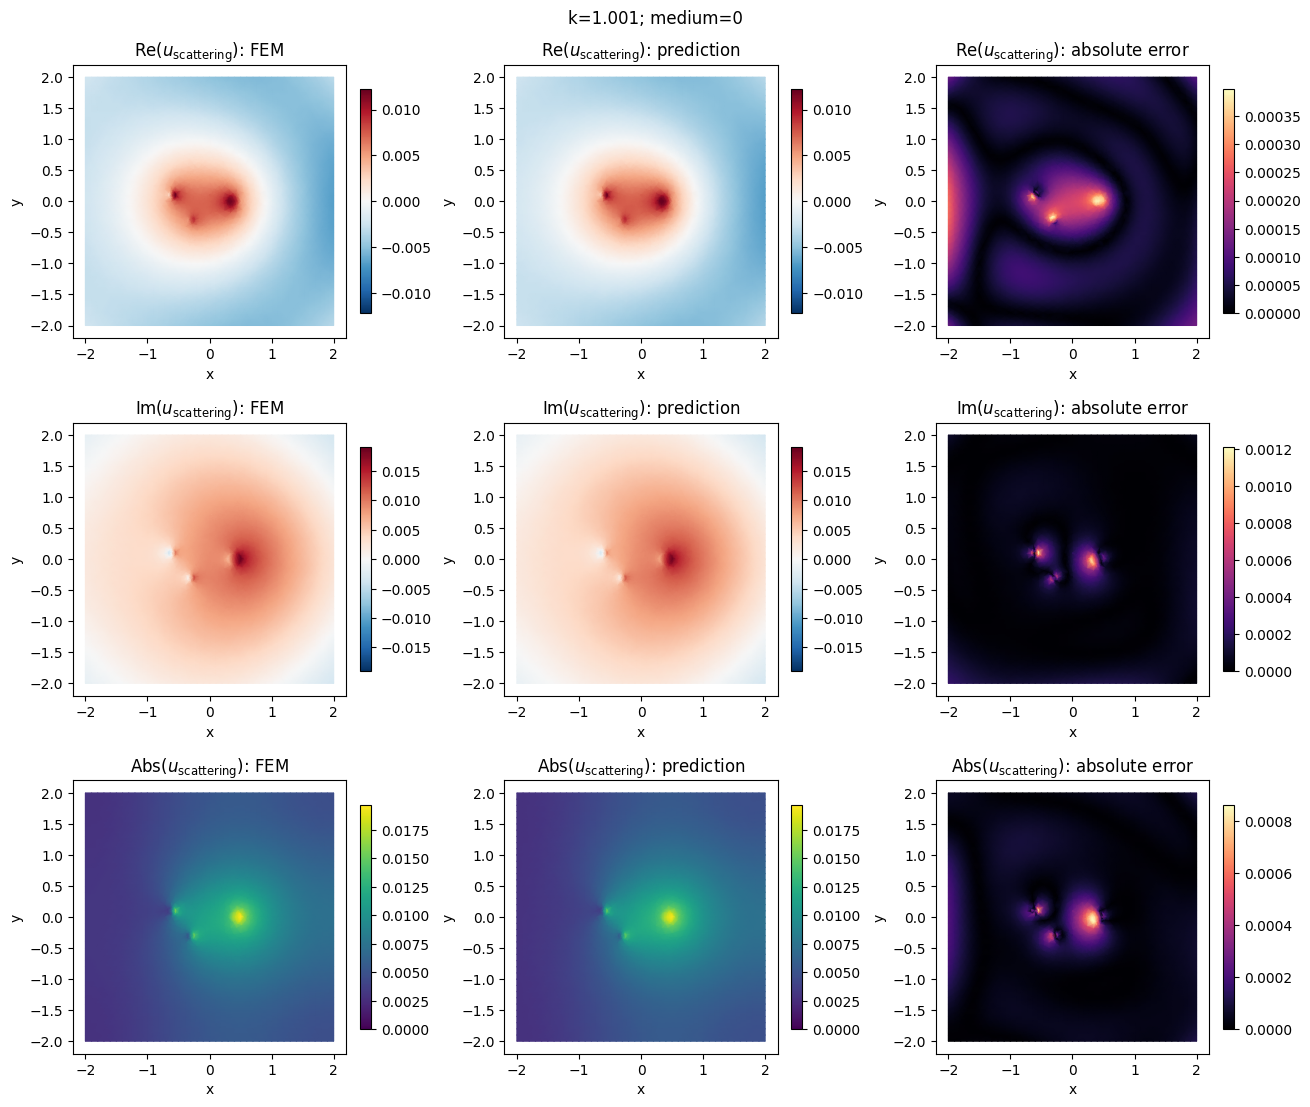

Self-contained checkpoint: /workspace/multiscale-fem-scattering/neural_operator/runs/static_low_frequency_1000x8/svd/model.pt


In [ ]:
# Re, Im и Abs: FEM / предсказание / абсолютная ошибка.
test = dataset.split_indices()[2]
index = int(test[0])
prediction = predictor.predict_dataset(dataset, [index])[0]
figure = plot_prediction(dataset, index, prediction)
figure.savefig(OUT / 'prediction.png', dpi=160)
plt.show()
print('Self-contained checkpoint:', OUT / 'model.pt')


Модель, базисы, нормализация, геометрия и архитектура находятся в одном `model.pt`; история и метрики сохранены рядом. Отдельный [Inference.ipynb](../notebooks/Inference.ipynb) загружает этот файл в чистом ядре. Сопоставление всех методов: [Comparison.ipynb](../notebooks/Comparison.ipynb). Расширенный набор содержит 1000 частот × 8 направлений. Малый train loss не подтверждает перенос на новые среды; результаты старого пилота сохранены в docs/local_results.md.
